In [38]:
import pandas as pd

import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split , cross_val_score ,StratifiedKFold ,GridSearchCV

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")


In [27]:
df = pd.read_csv("Classified Data")

In [28]:
df.head()

,Unnamed: 0,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


In [29]:
df.drop("Unnamed: 0" , axis = 1 , inplace=True)

In [30]:
df.tail()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
995,1.010953,1.034006,0.853116,0.622460,1.036610,0.586240,0.746811,0.319752,1.117340,1.348517,1
996,0.575529,0.955786,0.941835,0.792882,1.414277,1.269540,1.055928,0.713193,0.958684,1.663489,0
997,1.135470,0.982462,0.781905,0.916738,0.901031,0.884738,0.386802,0.389584,0.919191,1.385504,1
998,1.084894,0.861769,0.407158,0.665696,1.608612,0.943859,0.855806,1.061338,1.277456,1.188063,1
999,0.837460,0.961184,0.417006,0.799784,0.934399,0.424762,0.778234,0.907962,1.257190,1.364837,1


In [31]:
x = df.drop("TARGET CLASS" , axis = 1)

In [32]:
y = df[["TARGET CLASS"]]

In [8]:
sc = StandardScaler()

In [9]:
x = sc.fit_transform(x)

In [10]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3)

In [11]:
kn =KNeighborsClassifier(n_neighbors=3)

In [12]:
kn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=3)

In [13]:
y_pred = kn.predict(x_test)

In [14]:
accuracy_score(y_test,y_pred)

0.93

In [15]:
# plotting the elbow curve to find the best value of k

In [16]:
error_rate = []

for k in range(1,12):
    
    kn = KNeighborsClassifier(n_neighbors=k)
    
    kn.fit(x_train,y_train)
    
    y_pred = kn.predict(x_test)
    
    error_rate.append(1-accuracy_score(y_test,y_pred))

In [17]:
error_rate

[0.07333333333333336,
 0.07666666666666666,
 0.06999999999999995,
 0.06333333333333335,
 0.06333333333333335,
 0.053333333333333344,
 0.06666666666666665,
 0.053333333333333344,
 0.07666666666666666,
 0.06000000000000005,
 0.06999999999999995]

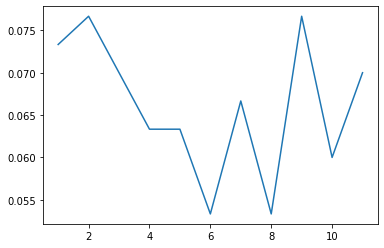

In [18]:
plt.plot(range(1,12) , error_rate)

In [19]:
score_knn = cross_val_score(kn , x , y , cv = 10)

In [20]:
np.mean(score_knn)

0.9329999999999998

In [21]:
# Performing stratifiedkfold

In [22]:
stf = StratifiedKFold(n_splits=10 , shuffle=True ,random_state=30)

In [23]:
accuracy = []

In [37]:
for train_index , test_index in stf.split(x,y):
    
#     print(train_index)
#     print(test_index)
    x_train,x_test = x[train_index],x[test_index]
    
#     y_train,y_test = y[train_index],y[test_index]
    
#     kn.fit(x_train,y_train)
    
   

KeyError: "None of [Int64Index([  1,   2,   3,   4,   5,   6,   7,   8,   9,  11,\n            ...\n            990, 991, 992, 993, 994, 995, 996, 997, 998, 999],\n           dtype='int64', length=900)] are in the [columns]"

In [34]:
x.head()

,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ
0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409
1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702
2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597
3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093
4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167


In [39]:
param_kn = {"n_neighbors" : [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]}

In [40]:
tuned_kn  = GridSearchCV(kn,param_kn,cv = 10)

In [41]:
tuned_kn.fit(x,y)

GridSearchCV(cv=10, estimator=KNeighborsClassifier(n_neighbors=11),
             param_grid={'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,
                                         13, 14, 15, 16, 17, 18, 19, 20]})

In [42]:
tuned_kn.best_params_

{'n_neighbors': 16}

In [43]:
tuned_kn.best_score_

0.9400000000000001